Una vez que logramos obener y visualizar que la volatilidad en mucho de los modelos y sobre todo en mercados financieros no es constante, debemos de preguntarnos como es que podemos modelar entonces el comportamiento de una serie, y compararlo de algún modo con el modelo de monte carlo que se encuentra al final en 1_montecarlo_real.

Al modelar Monte Carlo Simple se supone que los shock o rendimientos son modelados de manera aleatoria con una Normal de media y volatilidad constante, justamente lo que queremos cambiar es que la volatilidad si se modifica según sea la ventana de tiempo que se este viendo o modelando, algo así como que la volatilidad tiene memoria.Así el modelo de GARCH se encarga de modelar la volatilidad no los precios; que luego podemos terminar modelando con Monte Carlo o Browniano c:

En el modelo GARCH (Generalized Autoregressive Conditional Heteroskedasticity) modela la volatilidad con la siguiente ecuación:
$$\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2+\beta\sigma_{t-1}^2$$

Dónde $\omega$ es la volatilidad base, así esto implica que la volatilidad de hoy depende de shock's recientes y de votalidad pasada, (elevamos al cuadrado la normal para garantizar que el shock es positivo). A continuación compararemos la volatilidad dinámica o rodante (Rolling Volatility) con un modelo GARCH

In [57]:
from arch import arch_model # Paquetería arch para modelar garch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

tickers = ['SPY']

data = yf.download(tickers, start='2020-01-01', progress=False)['Close']

#Calculamos retornos logaritmos, esto debido a que pasamos de un modelo multiplicativo a aditivo. 
returns = data.pct_change().dropna()

asset_returns = returns['SPY'] * 100 #Multiplicamos por 100 para trabajar con porcentajes por que la libreria trabaja mejor con ello

In [58]:

rolling_vol = (
    returns
    .rolling(window=30)
    .std()
)

model = arch_model(
    asset_returns,
    vol='Garch',
    p=1,
    q=1
)

Trabajamos con un GARCH(p,q), dónde p=1 y q=1 es el número de rezagos de shocks y volatilidad respectivamente. 

In [59]:
results=model.fit()
print(results.conf_int())

Iteration:      1,   Func. Count:      6,   Neg. LLF: 17619521767.31124
Iteration:      2,   Func. Count:     14,   Neg. LLF: 1362545396.853898
Iteration:      3,   Func. Count:     21,   Neg. LLF: 2895.988768415853
Iteration:      4,   Func. Count:     28,   Neg. LLF: 2601.514364547678
Iteration:      5,   Func. Count:     36,   Neg. LLF: 2420.9079541943347
Iteration:      6,   Func. Count:     43,   Neg. LLF: 2286.328648925125
Iteration:      7,   Func. Count:     48,   Neg. LLF: 2286.3282261874165
Iteration:      8,   Func. Count:     53,   Neg. LLF: 2286.3282159434716
Iteration:      9,   Func. Count:     57,   Neg. LLF: 2286.3282159441933
Optimization terminated successfully    (Exit mode 0)
            Current function value: 2286.3282159434716
            Iterations: 9
            Function evaluations: 57
            Gradient evaluations: 9
             lower     upper
mu        0.049982  0.135658
omega     0.018921  0.088156
alpha[1]  0.092228  0.211125
beta[1]   0.739433  0.87

Dónde al ser $\alpha+\beta\approx1$ hay una volatilidad persistente, lo cuál es clásico en mercados financieros. 

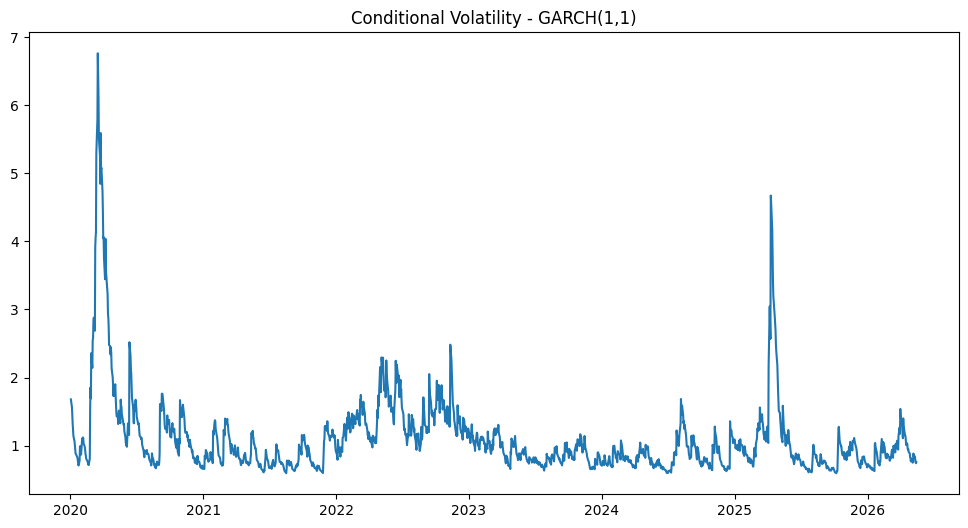

In [60]:
conditional_vol = results.conditional_volatility

plt.figure(figsize=(12,6))

plt.plot(conditional_vol)

plt.title('Conditional Volatility - GARCH(1,1)')

plt.show()


Que ahora comparamos con la Volatilidad Rodante:


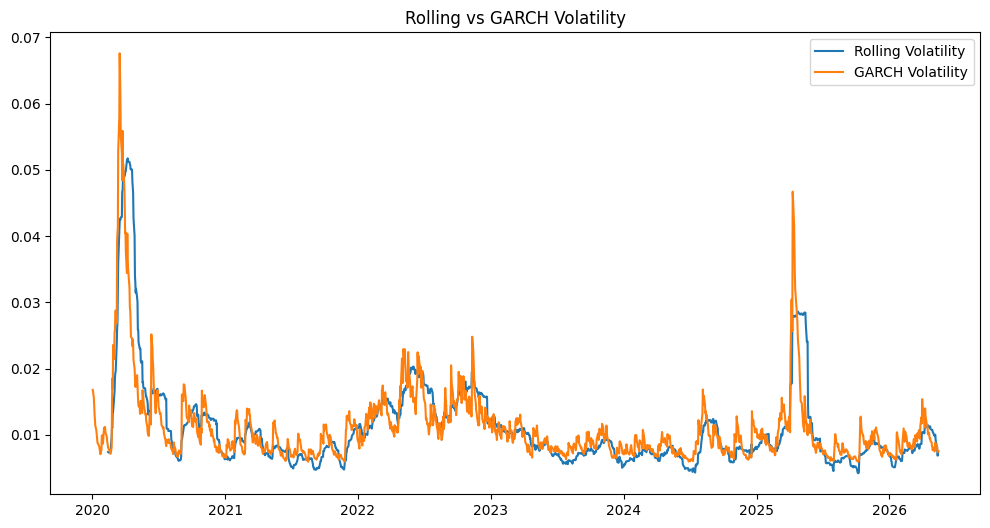

In [61]:
plt.figure(figsize=(12,6))

plt.plot(rolling_vol, label='Rolling Volatility')

plt.plot(
    conditional_vol / 100,
    label='GARCH Volatility'
)

plt.legend()

plt.title('Rolling vs GARCH Volatility')

plt.show()

Así el modelo GARCH guarda todo el comportamiento de la Volatilidad Rodante, por lo que podemos proceder a calcular el precio de los activos c: 

In [208]:
# ============================================
# 1. DESCARGAR DATOS
# ============================================
data = yf.download(
    'BTC-USD',
    start='2018-01-01',
    progress=False
)['Close']

# Precios reales del periodo test
real_prices = data.loc['2020-01-01':'2020-12-31']

# ============================================
# 2. RETORNOS 
# ============================================

returns = data.pct_change().dropna()

# ============================================
# 3. TRAIN / TEST
# ============================================

train = returns.loc[:'2019-12-31']
test = returns.loc['2020-01-01':'2020-12-31']

train_scaled = train * 100

# ============================================
# 4. MODELO GARCH(1,1)
# ============================================

model = arch_model(
    train_scaled,
    mean='AR',
    lags=1,
    vol='Garch',
    p=1,
    q=1
)

results = model.fit(disp='off')

# ============================================
# 5. PARÁMETROS HISTÓRICOS
# ============================================

mu = train.mean().values[0]

# Último precio conocido
S0 = float(data.loc[:'2019-12-31'].iloc[-1])

# Horizonte
n_days = len(test)

# Número de simulaciones
n_simulations = 50

# ============================================
# 6. FORECAST GARCH
# ============================================

forecast = results.forecast(horizon=n_days)

forecast_mean = forecast._mean.values[-1]/100
forecast_variance = forecast.variance.values[-1]


forecast_vol = np.sqrt(forecast_variance) / 100

C:\Users\emili\AppData\Local\Temp\ipykernel_15352\3621692232.py:50: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  S0 = float(data.loc[:'2019-12-31'].iloc[-1])


In [209]:
# ============================================
# 7. MONTE CARLO CON GARCH
# ============================================

simulations = np.zeros((n_days + 1, n_simulations))

for sim in range(n_simulations):

    prices = [S0]

    for t in range(n_days):

        # Shock aleatorio
        z = np.random.normal()

        # Volatilidad dinámica GARCH
        mu_t = float(forecast_mean[t])
        sigma_t = float(forecast_vol[t])

        # Retorno discreto simulado
        daily_return = np.random.normal(
            loc=mu_t,
            scale=sigma_t
        )

        # Actualización discreta del precio
        next_price = prices[-1] * (1 + daily_return)

        prices.append(next_price)

    simulations[:, sim] = prices

mean_path = simulations.mean(axis=1)


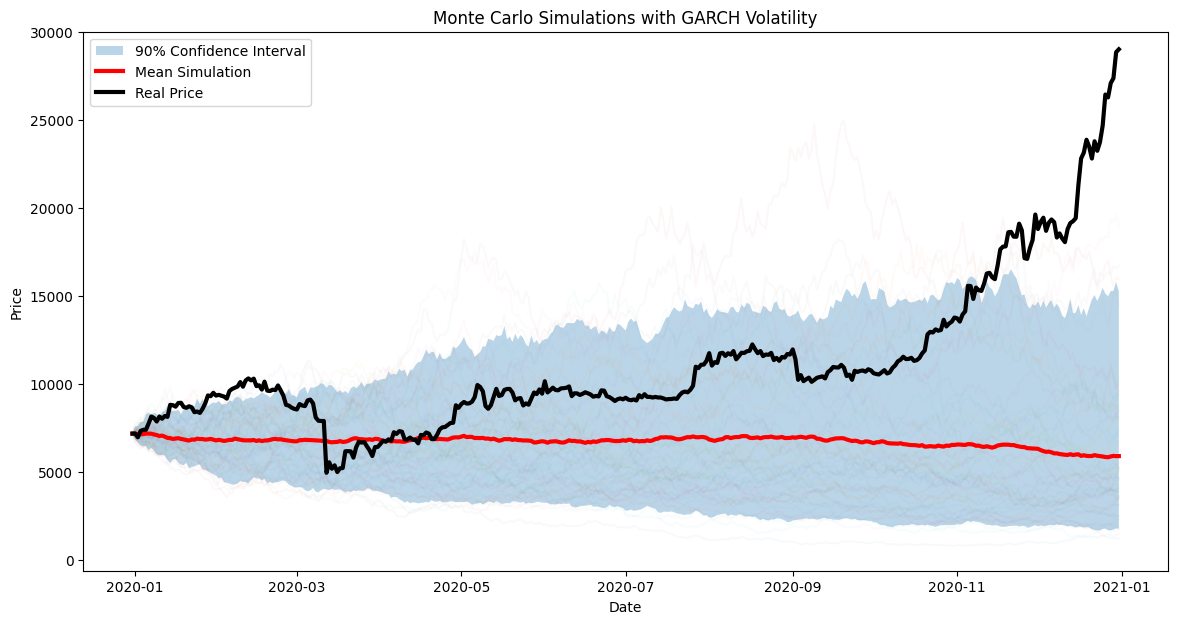

In [212]:
# ============================================
# 8. GRAFICAR SIMULACIONES
# ============================================
plot_index = [train.index[-1]] + list(test.index)
# Percentiles
p5 = np.percentile(simulations, 5, axis=1)
p95 = np.percentile(simulations, 95, axis=1)

plt.figure(figsize=(14,7))

# Banda de confianza
plt.fill_between(
    plot_index,
    p5,
    p95,
    alpha=0.3,
    label='90% Confidence Interval'
)

# Simulaciones individuales
plt.plot(
    plot_index,
    simulations,
    alpha=0.03
)

# Trayectoria promedio
plt.plot(
    plot_index,
    mean_path,
    color="red",
    linewidth=3,
    label='Mean Simulation'
)

# Precio real
plt.plot(
    plot_index,
    np.concatenate([
        [S0],
        real_prices.values.flatten()
    ]),
    color='black',
    linewidth=3,
    label='Real Price'
)

plt.title('Monte Carlo Simulations with GARCH Volatility')

plt.xlabel('Date')
plt.ylabel('Price')
plt.ylim(top=30000)

plt.legend()

plt.show()

Que al compararlo con el modelo que no considera volatilidad variante:
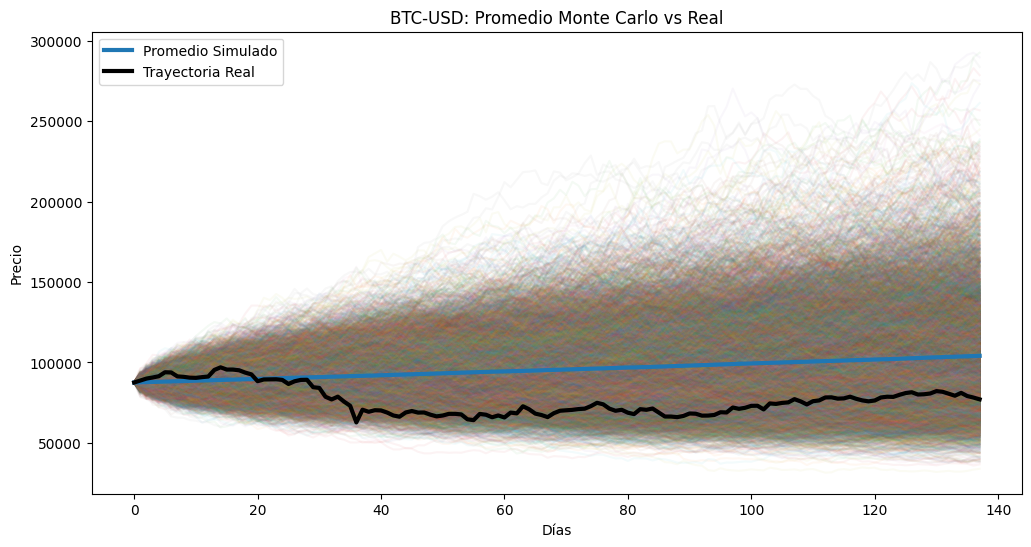